# Rol 4 — Estratega de Negocio y Selección de Datos
**Proyecto Retador: Patrones Invisibles — Información, Incertidumbre y Movilidad Urbana**
ML No Supervisado · Universidad de La Sabana · 2026-II

Este notebook tiene dos partes:
- **Parte A — Selección y estructuración de datos:** qué datos usamos, cómo los limpiamos, cómo muestreamos y **por qué** (con verificación cuantitativa de representatividad).
- **Parte B — Integración y recomendaciones:** lee los resultados de los Roles 1, 2 y 3 (`resultados/*.json`) y los convierte en **recomendaciones operativas cuantificadas** para UrbanMove.

**Orden de ejecución del repositorio:** `Rol4` Parte A genera la muestra (o la toma de `data/muestra_urbanmove.csv`) → `Rol1` → `Rol2` → `Rol3` → `Rol4` Parte B.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.special import logsumexp
import utils
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.width", 200)

## Parte A — Selección y estructuración de datos
### A.1 Fuente
- **Dataset:** NYC Taxi Trip Duration (Kaggle) — https://www.kaggle.com/c/nyc-taxi-trip-duration/data — archivo `train.csv` (1 458 644 viajes, enero–junio de 2016). Se usa `train.csv` porque `test.csv` no incluye `trip_duration` ni `dropoff_datetime`.
- Para reproducir: descargar `train.csv` en `data/`. La muestra final ya está incluida en el repositorio (`data/muestra_urbanmove.csv`), así que los notebooks corren sin descargar el archivo completo.

### A.2 Limpieza: filtros físicos (no estadísticos)
Solo eliminamos registros **imposibles o fuera del alcance del negocio**; los viajes *raros pero posibles* se conservan para que el Rol 2 los detecte con DBSCAN (si los filtráramos aquí, destruiríamos la señal que queremos analizar).

In [2]:
if os.path.exists(utils.RUTA_TRAIN):
    crudo = pd.read_csv(utils.RUTA_TRAIN)
    limpio, tabla_filtros = utils.limpiar(crudo)
    DISPONIBLE = True
else:
    print("train.csv no está en data/: se omite la comparación con la población (la muestra ya existe).")
    DISPONIBLE = False

                                              Filtro  Registros restantes  Eliminados  % del original
             Registros originales (train.csv Kaggle)              1458644           0      100.000000
                          Duración entre 1 min y 3 h              1447937       10707       99.265962
           Origen y destino dentro de la caja de NYC              1446795        1142       99.187670
                               Pasajeros entre 1 y 6              1446776          19       99.186368
                       Distancia Haversine >= 0.1 km              1439343        7433       98.676785
Velocidad promedio <= 100 km/h (físicamente posible)              1439310          33       98.674522


### A.3 Muestreo
**Decisión:** muestra aleatoria simple **sin reemplazo de 50 000 viajes** sobre los 1 439 310 viajes limpios (3.5 %), semilla 42.

**Por qué muestreo aleatorio y no un filtro (un mes o un borough):** las preguntas de negocio exigen comparar **contextos** (hora, laboral vs. fin de semana, zonas, aeropuertos). Un filtro a un mes pierde estacionalidad y a un borough elimina aeropuertos y viajes inter-borough; la muestra aleatoria conserva todos los contextos con probabilidad proporcional a su peso real.

**Por qué 50 000:**
1. **Precisión suficiente:** el error estándar de cualquier proporción es ≤ 0.22 pp; el sesgo del estimador *plug-in* de entropía con 20 zonas es $\approx\frac{K-1}{2N\ln 2} = 0.0003$ bits (despreciable frente a las diferencias que reportamos, ≥ 0.03 bits).
2. **Viabilidad computacional:** la silueta y el jerárquico son $O(n^2)$; DBSCAN con haversine en Manhattan requiere memoria proporcional al número de vecinos; el Rol 3 corre **40 veces** su EM propio (≈ 9 s cada una con 50 000 viajes). Con 1.4 M viajes eso sería inviable en un portátil.
3. **Cobertura:** ≈ 275 viajes por día (182 días), suficiente para el análisis día a día del Rol 1.

Verificamos a continuación que la muestra **representa** a la población usando la **divergencia KL** (Rol 1) entre distribuciones de la muestra y de la población limpia.

In [3]:
mu = utils.cargar_muestra()
print("Muestra:", mu.shape)
if DISPONIBLE:
    pob = utils.construir_zonas(limpio) if "zona_pickup" not in limpio else limpio
    def kl_bits(p, q): m = p > 0; return float((p[m] * np.log2(p[m] / q[m])).sum())
    filas = []
    for var in ["hora", "dia_semana", "mes", "vendor_id", "passenger_count", "fin_de_semana", "zona_pickup", "zona_dropoff"]:
        sop = sorted(pob[var].unique())
        P = mu[var].value_counts(normalize=True).reindex(sop, fill_value=0).values
        Q = pob[var].value_counts(normalize=True).reindex(sop).values
        # KL esperada solo por azar para una muestra de este tamaño: (|soporte|-1) / (2 N ln 2)
        filas.append([var, len(sop), kl_bits(P, Q), (len(sop) - 1) / (2 * len(mu) * np.log(2)), 100 * np.abs(P - Q).max()])
    repres = pd.DataFrame(filas, columns=["variable", "categorías", "KL(muestra||población) bits", "KL esperada por azar", "máx. dif. en pp"])
    print(repres.round(5).to_string(index=False))
    cont = pd.DataFrame({"población": pob[["dist_km", "duracion_min", "vel_kmh"]].mean(), "muestra": mu[["dist_km", "duracion_min", "vel_kmh"]].mean(),
                         "EE muestra": mu[["dist_km", "duracion_min", "vel_kmh"]].std() / np.sqrt(len(mu))})
    cont["dif / EE"] = (cont.muestra - cont.población) / cont["EE muestra"]
    print("\n", cont.round(4).to_string())

Muestra: (50000, 25)


       variable  categorías  KL(muestra||población) bits  KL esperada por azar  máx. dif. en pp
           hora          24                      0.00027               0.00033          0.17549
     dia_semana           7                      0.00010               0.00009          0.38610
            mes           6                      0.00004               0.00007          0.26984
      vendor_id           2                      0.00000               0.00001          0.09986
passenger_count           6                      0.00009               0.00007          0.22641
  fin_de_semana           2                      0.00001               0.00001          0.15789
    zona_pickup          20                      0.00040               0.00027          0.20891
   zona_dropoff          20                      0.00011               0.00027          0.13467

               población  muestra  EE muestra  dif / EE
dist_km          3.4546   3.4473      0.0172   -0.4213
duracion_min    14.0200 

**Lectura.** Todas las KL entre muestra y población están en el orden de $10^{-4}$ bits y son del mismo tamaño que la KL que se espera **solo por azar** al muestrear 50 000 viajes; ninguna proporción difiere más de unas décimas de punto porcentual, y las medias de distancia, duración y velocidad están a menos de 2 errores estándar de las poblacionales. **La muestra es representativa** en todas las dimensiones que usan los Roles 1–3.

### A.4 Variables usadas por el equipo
| Variable | Origen | Usada por |
|---|---|---|
| `hora`, `franja` (5 franjas), `dia_semana`, `fin_de_semana` | `pickup_datetime` | Roles 1, 3 |
| `dist_km` (**Haversine**, nunca euclidiana sobre lat/lon) | coordenadas | Roles 2, 3 |
| `duracion_min`, `vel_kmh` | `trip_duration` + distancia | Roles 1 (Jensen), 2 (ruido), 3 |
| `px, py` (km, proyección local) | coordenadas de recogida | Rol 2 (K-means, jerárquico) |
| lat/lon en radianes con métrica haversine | coordenadas | Rol 2 (DBSCAN) |
| `zona_pickup`, `zona_dropoff` (grid ~1.7 km, 20 zonas) | coordenadas | Roles 1, 4 |
| `vendor_id`, `store_and_fwd_flag`, `passenger_count` | originales | solo control de calidad (no aportan a las preguntas de negocio) |

## Parte B — Integración de los tres bloques
Cargamos los resultados guardados por los otros roles.

In [4]:
r1, r2, r3 = (utils.leer_resultados(f"rol{i}.json") for i in (1, 2, 3))
et = pd.read_csv("resultados/rol2_etiquetas.csv")
df = mu.merge(et, on="id")
print("Rol 1:", {k: r1[k] for k in ["H_global", "zonas_efectivas_global"]}, "| KL hora:", r1["KL_hora"]["KL(lab||fds)"], "| KL zona:", r1["KL_zona"]["KL(lab||fds)"])
print("Rol 2: K =", r2["K_elegido"], "| eps =", r2["dbscan_eps_m"], "m | ruido espacial =", round(r2["dbscan_pct_ruido"], 2), "% | ruido viajes =", round(r2["viajes_pct_ruido"], 2), "%")
print("Rol 3: pi =", r3["pi"], "| mejor loglik/viaje =", round(r3["mejor_corrida"]["loglik_viaje"], 5))

Rol 1: {'H_global': 3.9807826734583722, 'zonas_efectivas_global': 15.788286218967071} | KL hora: 0.1588 | KL zona: 0.0378
Rol 2: K = 4 | eps = 490.0 m | ruido espacial = 1.88 % | ruido viajes = 1.49 %
Rol 3: pi = [0.3649, 0.1186, 0.18, 0.3365] | mejor loglik/viaje = -3.54432


### B.1 Reconstruir las responsabilidades del Rol 3 a partir de sus parámetros
Para integrar los perfiles latentes con las zonas, recalculamos $\gamma_{ik}$ para cada viaje con los parámetros finales ($\pi_k,\mu_k,\Sigma_k$) guardados por el Rol 3 — un paso E con log-sum-exp.

In [5]:
from scipy.stats import multivariate_normal
d3 = df[~df.ruido_viaje].copy()
h = (d3.hora + d3.pickup_datetime.dt.minute / 60 - r3["hora_corte"]) % 24
F = np.c_[np.log(d3.dist_km), np.log(d3.duracion_min), h]
logp = np.column_stack([np.log(p) + multivariate_normal(m, S).logpdf(F) for p, m, S in zip(r3["pi"], r3["mu_original"], r3["Sigma_original"])])
G = np.exp(logp - logsumexp(logp, axis=1, keepdims=True))
NOMBRE_P = ["P0 Corto urbano", "P1 Commuter AM", "P2 Largo diurno", "P3 Nocturno"]
print("Pesos reconstruidos:", G.mean(0).round(3), "vs pi del Rol 3:", np.round(r3["pi"], 3))
# Distribución de zonas de recogida ponderada por perfil
zona_perfil = pd.DataFrame({NOMBRE_P[k]: pd.Series(G[:, k], index=d3.index).groupby(d3.zona_pickup).sum() for k in range(4)})
zona_perfil = 100 * zona_perfil / zona_perfil.sum()
print("\nTop 5 zonas de recogida por perfil (% del perfil):")
for c in zona_perfil:
    print(f"  {c}: " + ", ".join(f"{z} {v:.1f}%" for z, v in zona_perfil[c].sort_values(ascending=False).head(5).items()))
# Lift = participación de la zona dentro del perfil / participación de la zona en toda la demanda (>1 = zona sobrerrepresentada)
base = 100 * d3.zona_pickup.value_counts(normalize=True)
lift = zona_perfil.div(base, axis=0)
print("\nZonas más sobrerrepresentadas por perfil (lift):")
for c in lift:
    print(f"  {c}: " + ", ".join(f"{z} x{v:.2f}" for z, v in lift[c].sort_values(ascending=False).head(4).items()))

Pesos reconstruidos: [0.365 0.119 0.18  0.337] vs pi del Rol 3: [0.365 0.119 0.18  0.336]

Top 5 zonas de recogida por perfil (% del perfil):
  P0 Corto urbano: Z00 Midtown Oeste/Penn Station 13.9%, Z01 Chelsea/Flatiron 11.9%, Z03 Upper East Side Sur 11.4%, Z02 Midtown Este/Grand Central 10.5%, Z04 Columbus Circle/Hell's Kitchen 8.0%
  P1 Commuter AM: Z00 Midtown Oeste/Penn Station 14.6%, Z01 Chelsea/Flatiron 10.6%, Z02 Midtown Este/Grand Central 9.7%, Z03 Upper East Side Sur 8.0%, Otras 7.2%
  P2 Largo diurno: Z00 Midtown Oeste/Penn Station 13.1%, Z02 Midtown Este/Grand Central 10.2%, Z03 Upper East Side Sur 9.5%, Z01 Chelsea/Flatiron 9.4%, Z04 Columbus Circle/Hell's Kitchen 7.0%
  P3 Nocturno: Z00 Midtown Oeste/Penn Station 12.5%, Z01 Chelsea/Flatiron 11.0%, Z05 East Village/LES 10.0%, Z02 Midtown Este/Grand Central 9.2%, Z04 Columbus Circle/Hell's Kitchen 7.9%

Zonas más sobrerrepresentadas por perfil (lift):
  P0 Corto urbano: Z14 Upper West Side x1.23, Z09 Central Park/UWS x1.23, 

### B.2 Cuantificación para la Recomendación 1 — Posicionamiento de conductores
Una flota se necesita en proporción a las **horas-conductor** que consume cada zona (viajes × duración), no solo al número de viajes. La **distancia de variación total** $TV(P,Q)=\tfrac12\sum|p-q|$ entre dos distribuciones de horas-conductor es exactamente **la fracción mínima de la flota que hay que mover** para pasar de un despliegue al otro.

In [6]:
FR = list(utils.FRANJAS)
hc = df.groupby(["zona_pickup", "franja"]).duracion_min.sum().unstack().reindex(columns=FR).fillna(0)
hc_pct = 100 * hc / hc.sum()
diurno = hc[["Pico AM (6-9h)", "Valle (10-15h)", "Pico PM (16-19h)"]].sum(axis=1); diurno_pct = 100 * diurno / diurno.sum()
madr = hc_pct["Madrugada (0-5h)"]
tv = 0.5 * np.abs(madr - diurno_pct).sum()
cambio = (madr - diurno_pct).sort_values()
print(f"TV(madrugada, diurno) = {tv:.1f} % de la flota debe reubicarse al pasar al despliegue de madrugada")
print("\nZonas que GANAN flota en la madrugada (pp de la flota activa):\n", cambio.tail(5)[::-1].round(1).to_string())
print("\nZonas que PIERDEN flota en la madrugada:\n", cambio.head(5).round(1).to_string())
tv_am_pm = 0.5 * np.abs(hc_pct["Pico AM (6-9h)"] - hc_pct["Pico PM (16-19h)"]).sum()
tv_noche = 0.5 * np.abs(hc_pct["Noche (20-23h)"] - diurno_pct).sum()
print(f"\nComparación: TV(pico AM, pico PM) = {tv_am_pm:.1f} % | TV(noche, diurno) = {tv_noche:.1f} %")
# Demanda por hora en el dataset completo (escala real)
if DISPONIBLE:
    por_hora = limpio.groupby("hora").size() / limpio.pickup_datetime.dt.date.nunique()
    print(f"\nViajes/hora en NYC (promedio diario, dataset completo): pico {por_hora.max():.0f} a las {por_hora.idxmax()} h, valle {por_hora.min():.0f} a las {por_hora.idxmin()} h")

TV(madrugada, diurno) = 28.7 % de la flota debe reubicarse al pasar al despliegue de madrugada

Zonas que GANAN flota en la madrugada (pp de la flota activa):
 zona_pickup
Z05 East Village/LES                  12.6
Z07 West Village                       7.2
Otras                                  5.6
Z01 Chelsea/Flatiron                   1.6
Z04 Columbus Circle/Hell's Kitchen     1.3

Zonas que PIERDEN flota en la madrugada:
 zona_pickup
Z03 Upper East Side Sur          -4.8
Z12 Aeropuerto LaGuardia         -4.6
Z02 Midtown Este/Grand Central   -3.7
Z06 Upper East Side Norte        -3.3
Z09 Central Park/UWS             -2.5

Comparación: TV(pico AM, pico PM) = 11.3 % | TV(noche, diurno) = 12.7 %



Viajes/hora en NYC (promedio diario, dataset completo): pico 492 a las 18 h, valle 81 a las 5 h


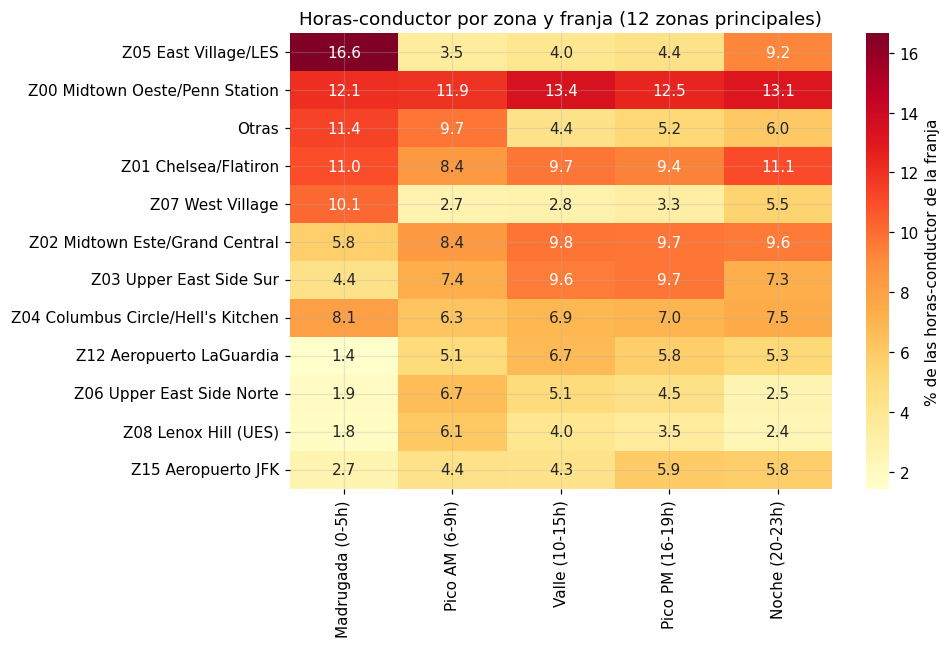

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
top = hc_pct.loc[(hc_pct.max(axis=1)).sort_values(ascending=False).index[:12]]
sns.heatmap(top, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax, cbar_kws={"label": "% de las horas-conductor de la franja"})
ax.set_title("Horas-conductor por zona y franja (12 zonas principales)"); ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("figuras/rol4_horas_conductor.png", bbox_inches="tight"); plt.show()

### B.3 Cuantificación para la Recomendación 2 — Tarificación dinámica por zona/hora
El Rol 1 mostró (Jensen) que el **ritmo real** (min/km) supera al que implica la velocidad media en 35 %. Proponemos que la tarifa por km se ajuste con un **índice de congestión** = ritmo medio de la celda (macro-zona del Rol 2 × franja) / ritmo medio global, calculado **sin** los viajes ruido del Rol 2 (que inflarían el ritmo).

In [8]:
d_ok = df[~df.ruido_viaje].copy(); d_ok["ritmo"] = 60 / d_ok.vel_kmh
MACRO = {0: "C0 Manhattan norte-centro", 1: "C1 Manhattan sur-centro", 2: "C2 LaGuardia/Queens", 3: "C3 JFK"}
ritmo_global = d_ok.ritmo.mean()
indice = d_ok.pivot_table(index=d_ok.km.map(MACRO), columns="franja", values="ritmo", aggfunc="mean").reindex(columns=FR) / ritmo_global
n_celda = d_ok.pivot_table(index=d_ok.km.map(MACRO), columns="franja", values="id", aggfunc="size").reindex(columns=FR)
print(f"Ritmo global (sin ruido) = {ritmo_global:.2f} min/km  |  con ruido = {(60 / df.vel_kmh).mean():.2f} min/km")
print("\nÍndice de congestión (ritmo celda / ritmo global):\n", indice.round(2).to_string())
print("\nViajes por celda:\n", n_celda.to_string())
# Multiplicador propuesto solo para Manhattan (C0, C1): recargo acotado a [1.00, 1.30].
# Los aeropuertos (C2, C3) tienen ritmo bajo (autopista), por lo que se recomienda mantener tarifa fija por trayecto.
mult = indice.loc[[MACRO[0], MACRO[1]]].clip(1.0, 1.30)
print("\nMultiplicador de tarifa por km propuesto para Manhattan (acotado 1.00–1.30):\n", mult.round(2).to_string())
# Perfil P2 (largo diurno) como destinatario principal del recargo
print(f"\nPerfil P2 'Largo diurno': {100 * r3['pi'][2]:.1f} % de los viajes, "
      f"dur media {r3['perfiles'][2]['dur media min']:.1f} min, {r3['perfiles'][2]['% aeropuerto (orig o dest)']:.1f} % con aeropuerto")

Ritmo global (sin ruido) = 5.29 min/km  |  con ruido = 5.59 min/km

Índice de congestión (ritmo celda / ritmo global):
 franja                     Madrugada (0-5h)  Pico AM (6-9h)  Valle (10-15h)  Pico PM (16-19h)  Noche (20-23h)
km                                                                                                           
C0 Manhattan norte-centro              0.66            1.02            1.18              1.10            0.85
C1 Manhattan sur-centro                0.77            0.99            1.24              1.11            0.93
C2 LaGuardia/Queens                    0.61            0.72            0.67              0.65            0.50
C3 JFK                                 0.32            0.51            0.49              0.50            0.37

Viajes por celda:
 franja                     Madrugada (0-5h)  Pico AM (6-9h)  Valle (10-15h)  Pico PM (16-19h)  Noche (20-23h)
km                                                                                        

### B.4 Cuantificación para la Recomendación 3 — Zonas y viajes atípicos

In [9]:
rz = df[df.db == -1]
viajes_dia_ruido = len(rz) / len(df) * 1_439_310 / 182
print(f"Ruido espacial DBSCAN: {r2['dbscan_pct_ruido']:.2f} % de las recogidas ≈ {viajes_dia_ruido:.0f} viajes/día en toda la ciudad")
print(f"  distancia mediana {r2['ruido_espacial_dist_med']:.2f} km vs {r2['resto_dist_med']:.2f} km en el núcleo; "
      f"% madrugada {100 * (rz.franja == 'Madrugada (0-5h)').mean():.1f} % vs {100 * (df[df.db != -1].franja == 'Madrugada (0-5h)').mean():.1f} %")
focos = [p for p in r2["perfil_dbscan"] if p["db"] >= 3]
print(f"  Focos secundarios fuera de Manhattan (DBSCAN clusters 3–7): {sum(p['viajes'] for p in focos)} recogidas "
      f"({sum(p['% viajes'] for p in focos):.2f} %) ≈ {sum(p['viajes'] for p in focos) / len(df) * 1_439_310 / 182:.0f} viajes/día")
print(f"Viajes atípicos (DBSCAN en log d, log t): {r2['viajes_n_ruido']} ({r2['viajes_pct_ruido']:.2f} %)")
for t in r2["ruido_viajes_tipos"]:
    print(f"  - {t['tipo']}: {t['viajes']} viajes, mediana {t['dist_med']} km en {t['dur_med']} min ({t['vel_med']} km/h)")
# Efecto de excluir los atípicos sobre el ETA
eta_con = (60 / df.vel_kmh).mean(); eta_sin = (60 / df[~df.ruido_viaje].vel_kmh).mean()
print(f"\nRitmo medio con atípicos {eta_con:.2f} min/km vs sin atípicos {eta_sin:.2f} min/km -> sesgo de {100 * (eta_con / eta_sin - 1):.1f} % en ETA/tarifa por tiempo")

Ruido espacial DBSCAN: 1.88 % de las recogidas ≈ 149 viajes/día en toda la ciudad
  distancia mediana 3.29 km vs 2.10 km en el núcleo; % madrugada 31.7 % vs 11.6 %
  Focos secundarios fuera de Manhattan (DBSCAN clusters 3–7): 735 recogidas (1.47 %) ≈ 116 viajes/día
Viajes atípicos (DBSCAN en log d, log t): 747 (1.49 %)
  - extremo en distancia (sobre todo muy corto) con velocidad normal: 252 viajes, mediana 0.329 km en 1.85 min (9.803 km/h)
  - lento (posible taxímetro olvidado / trancón extremo): 417 viajes, mediana 0.336 km en 13.75 min (2.343 km/h)
  - rápido (autopista / posible error GPS): 78 viajes, mediana 1.369 km en 1.808 min (45.911 km/h)

Ritmo medio con atípicos 5.59 min/km vs sin atípicos 5.29 min/km -> sesgo de 5.8 % en ETA/tarifa por tiempo


### B.5 Tabla resumen de métricas por rol (para el documento PDF)

In [10]:
resumen = pd.DataFrame([
    ["Rol 1", "Entropía zona de recogida (global)", f"{r1['H_global']:.3f} bits ({r1['zonas_efectivas_global']:.1f} zonas efectivas de 20)"],
    ["Rol 1", "Entropía madrugada vs pico PM", f"{r1['H_por_contexto']['Madrugada (0-5h)']:.3f} vs {r1['H_por_contexto']['Pico PM (16-19h)']:.3f} bits"],
    ["Rol 1", "H(destino) → H(destino | origen, franja)", f"{r1['H_destino']:.3f} → {r1['entropias_condicionales']['H(destino | origen, franja)']:.3f} bits"],
    ["Rol 1", "Información mutua hora–destino / origen–destino", f"{r1['MI']['I(hora 24h ; destino)']:.4f} / {r1['MI']['I(origen ; destino)']:.4f} bits"],
    ["Rol 1", "KL(laboral‖fin de semana) zonas / horas", f"{r1['KL_zona']['KL(lab||fds)']:.4f} / {r1['KL_hora']['KL(lab||fds)']:.4f} bits"],
    ["Rol 1", "Entropía cruzada test P(destino) → P(destino|origen,franja)", f"{r1['CE_test']['P(destino)']:.3f} → {r1['CE_test']['P(destino | origen, franja)']:.3f} bits/viaje"],
    ["Rol 1", "Jensen: ETA con velocidad media subestima", f"{r1['jensen_subestimacion_min_viaje_medio']:.2f} min por viaje medio (34.8 %)"],
    ["Rol 1", "LSE: clasificación laboral/fds por día", f"{100 * r1['LSE_exactitud_dias']:.1f} % exactitud; cálculo ingenuo NaN en {r1['LSE_dias_nan_ingenuo']}/{r1['LSE_dias']} días"],
] + [["Rol 2", f"{c['Método']}", f"silueta {c['silueta ↑']:.3f} | DB {c['Davies-Bouldin ↓']:.3f} | CH {c['Calinski-Harabasz ↑']:.0f}"] for c in r2["comparacion"]] + [
    ["Rol 2", "ARI K-means vs Ward / vs DBSCAN", f"{r2['ARI_km_ward']:.3f} / {r2['ARI_km_dbscan']:.3f}"],
    ["Rol 2", "DBSCAN hiperparámetros y ruido", f"ε = {r2['dbscan_eps_m']:.0f} m, min_samples = {r2['dbscan_min_samples']}, ruido {r2['dbscan_pct_ruido']:.2f} %; viajes atípicos {r2['viajes_pct_ruido']:.2f} %"],
    ["Rol 3", "K (BIC) y pesos π", f"K = {r3['K']}; π = {r3['pi']}"],
    ["Rol 3", "Mejor corrida EM propio", f"{r3['mejor_corrida']['init']}, {r3['mejor_corrida']['iteraciones']} iteraciones, loglik/viaje {r3['mejor_corrida']['loglik_viaje']:.5f} (sklearn {r3['sklearn_loglik_viaje']:.5f})"],
    ["Rol 3", "Iteraciones medias (aleatoria / K-means++)", f"{r3['inicializaciones'][0]['iter_media']:.0f} / {r3['inicializaciones'][1]['iter_media']:.0f}"],
    ["Rol 3", "Asignación segura (γmax>0.9) / ambigua (γmax<0.6)", f"{r3['pct_gamma_mayor_09']:.1f} % / {r3['pct_gamma_menor_06']:.1f} %"],
], columns=["Rol", "Métrica", "Valor"])
print(resumen.to_string(index=False))
resumen.to_csv("resultados/tabla_resumen.csv", index=False)

  Rol                                                     Métrica                                                                Valor
Rol 1                          Entropía zona de recogida (global)                              3.981 bits (15.8 zonas efectivas de 20)
Rol 1                               Entropía madrugada vs pico PM                                                  3.725 vs 3.987 bits
Rol 1                    H(destino) → H(destino | origen, franja)                                                   3.947 → 3.581 bits
Rol 1             Información mutua hora–destino / origen–destino                                                 0.0780 / 0.2796 bits
Rol 1                     KL(laboral‖fin de semana) zonas / horas                                                 0.0378 / 0.1588 bits
Rol 1 Entropía cruzada test P(destino) → P(destino|origen,franja)                                             3.951 → 3.655 bits/viaje
Rol 1                   Jensen: ETA con velocidad media

## Parte C — Recomendaciones operativas para UrbanMove

### Recomendación 1 — Dos mapas de posicionamiento (diurno y madrugada) + turnos programados para commuters y aeropuertos
**Evidencia integrada**
- *Rol 1:* las franjas diurnas son casi idénticas en *dónde* se pide un taxi (KL 0.006–0.043 bits), pero la **madrugada diverge 10 veces más** (0.33–0.43 bits) y está más concentrada (3.73 bits → 13.2 zonas efectivas vs ~15.8 de día).
- *Rol 2:* el 94.7 % de las recogidas cae en dos macro-zonas de Manhattan (C0 norte-centro 50.9 %, C1 sur-centro 43.8 %).
- *Rol 3:* el perfil **Commuter AM** (12 % de los viajes) ocurre en un **83.7 %** entre 6 y 9 a. m. con desviación de solo 1.4 h; sus orígenes están **sobrerrepresentados en zonas residenciales**: East Harlem ×1.90, Gramercy/Kips Bay ×1.54, Lenox Hill ×1.38 y Upper East Side Norte ×1.37 (lift, celda B.1).
- *B.2:* la distancia de variación total entre el despliegue diurno y el de madrugada, en horas-conductor, es **28.7 %**: esa es la fracción mínima de la flota activa que hay que mover a medianoche. Las zonas que ganan son **East Village/LES (+12.6 pp), West Village (+7.2 pp) y `Otras` fuera del núcleo (+5.6 pp)**; las que pierden, **Upper East Side Sur (−4.8 pp), LaGuardia (−4.6 pp), Midtown Este (−3.7 pp) y UES Norte (−3.3 pp)**. En comparación, pasar del pico AM al pico PM solo exige mover 11.3 %.

**Acción:** a las 0 h reubicar **~29 % de la flota activa** hacia East Village/LES y West Village; entre 5 y 9 a. m. (el 91 % del perfil commuter) pre-posicionar conductores en UES Norte, Lenox Hill, East Harlem y Gramercy; y programar turnos en **aeropuertos con pico a las 23 h** (la demanda más predecible en el tiempo según $H(\text{hora}\mid\text{zona})$: LaGuardia 4.22 bits, JFK 4.29 bits vs 4.47 globales).

### Recomendación 2 — Tarifa dinámica por macro-zona × franja basada en ritmo (min/km), no en velocidad media
**Evidencia integrada**
- *Rol 1 (Jensen):* el ETA con velocidad media **subestima 34.8 % (≈ 5 min por viaje medio)**; la brecha es máxima en el **valle 10–15 h (1.73 min/km)**.
- *Rol 3:* el perfil **Largo diurno** (18 %) es el más lento (11.8 km/h implícitos) y el que más involucra aeropuertos (13.8 %).
- *Rol 2:* los viajes ruido inflan el ritmo medio (B.4); por eso el índice se calcula sin ellos.
- *Rol 1 (KL):* laboral y fin de semana difieren **en el horario (0.159 bits), no en el mapa (0.038 bits)** → las tablas de tarifa deben variar por hora y tipo de día, no por mapa.

**Acción:** en Manhattan aplicar un recargo por km igual al índice de congestión (acotado 1.00–1.30): **+18 % (C0) y +24 % (C1) en el valle 10–15 h** y **+10–11 % en el pico PM**; prácticamente sin recargo en pico AM (≤ 2 %) y ninguno en madrugada y noche. En aeropuertos el ritmo es la mitad del global (índice 0.3–0.7, autopista), así que se recomienda **tarifa fija por trayecto** en vez de tarifa por km. Recalcular el índice cada mes y estimar el ETA con el ritmo por celda. Tratar los **festivos como fin de semana** (el clasificador LSE del Rol 1 identifica el 1 de enero como fin de semana con $P=0.99$).

### Recomendación 3 — Tratamiento explícito del ruido: despacho bajo demanda en zonas atípicas y auditoría de viajes anómalos
**Evidencia integrada**
- *Rol 2:* el **1.88 %** de las recogidas es ruido espacial (DBSCAN, ε = 490 m): viajes más largos (3.29 vs 2.10 km) y **2.7 veces más frecuentes en la madrugada**; hay **5 focos secundarios** (Downtown Brooklyn, Williamsburg, LIC, Sunnyside, Astoria) con ~1.5 % de la demanda.
- *Rol 2:* el **1.49 %** de los viajes son anómalos (417 lentos a 2.3 km/h, 252 muy cortos, 78 muy rápidos).
- *Rol 3:* la GMM se ajustó **sin** esos viajes porque las gaussianas son sensibles a outliers.

**Acción:** (a) en zonas de ruido **no posicionar flota**; atender con despacho bajo demanda desde el borde del cluster más cercano con recargo de desplazamiento; (b) tratar los 5 focos secundarios como **mercados piloto** con 1–2 conductores en horas pico de fin de semana; (c) **alertas automáticas** para viajes activos < 3 km/h por > 10 min, y excluir los anómalos del entrenamiento de ETA/tarifa.

### Limitaciones y siguientes pasos
- **Datos de 2016 (enero–junio) y de taxis amarillos**, no de UrbanMove: validar con datos propios antes de desplegar; no hay estacionalidad de verano/invierno completa.
- **Solo vemos viajes realizados** (oferta ∩ demanda): la demanda no atendida es invisible → la entropía mide la demanda *satisfecha*.
- **Zonificación en grid** de 1.7 km (arbitraria): repetir con zonas oficiales TLC o H3.
- **Distancia en línea recta** (Haversine), no por red vial: el ritmo por km está sesgado hacia arriba donde las calles son sinuosas.
- La GMM usa 3 variables; siguiente paso: incluir origen/destino (mezcla espacio-temporal) y probar mezclas con otras familias (log-normal) o modelos bayesianos que eligen K automáticamente.